# Quantum 101 and Qiskit: Hands-on

**Qiskit Fall Fest 2026 · UC Irvine**

- Difficulty: Beginner
- QPU time usage: about 11 s (one job of nine small circuits; optional)

Welcome, Anteaters! The goal of this hands-on is to get you ready for your quantum journey. You will

1. install Qiskit,
2. set up an IBM Quantum Platform account (an `API key` and an instance `CRN`) so you can use a real quantum computer,
3. build your first quantum circuits and see their states,
4. solve a short quantum-state quiz, and
5. run your circuits on a simulator **and** on a real IBM quantum computer, then compare the results.

| Talk demo step | Where it happens here |
|---|---|
| Define (qubits, gates, measurement) | Section 3 |
| Visualize (circuit diagrams, qsphere) | Sections 3–4 |
| Simulate | Section 5, *Execute on a simulator* |
| Transpile | Section 5, *Optimize* |
| Execute on a quantum computer | Section 5, *Execute on the quantum computer* |
| Analyze | Section 5, *Post-process* |

> **No account yet?** Sections 3 and 4 run entirely on your laptop, and Section 5 has a noisy simulator of a real IBM device you can use instead of hardware.

## 1. First things first: Qiskit

### What is Qiskit

Qiskit stands for **Quantum Information Software Kit**, an open-source, Python-based software development kit (SDK) for quantum computing developed by IBM Research.

The **[Qiskit SDK](https://www.ibm.com/quantum/qiskit)** is an open-source, high-performance software stack for working with quantum computers at the level of circuits, operators, and primitives. It lets anyone get good performance from real quantum computers in the computing environment they already use.

Beyond the SDK, Qiskit includes services such as the [IBM Quantum Compute service (formerly Qiskit Runtime)](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/runtime-service), which runs your circuits on IBM quantum computers through the cloud using primitives that manage error suppression and mitigation, and [Qiskit Functions](https://quantum.cloud.ibm.com/docs/en/guides/functions), a catalog of IBM and third-party services for application workloads. Whether you are a quantum software developer, an experimentalist, a computational scientist, or just getting started, Qiskit lets you work at the level of abstraction that suits you.

### Install Qiskit

Qiskit needs Python 3.10 or newer. Check your version:

In [1]:
from platform import python_version

print(python_version())

3.12.3


Install Qiskit, the IBM Quantum client, and the Aer simulator (run once):

In [2]:
%pip install --upgrade 'qiskit[visualization]' qiskit-ibm-runtime qiskit-aer

Note: you may need to restart the kernel to use updated packages.


In [3]:
import qiskit, qiskit_ibm_runtime, qiskit_aer

print(f"Qiskit version:             {qiskit.__version__}")
print(f"qiskit-ibm-runtime version: {qiskit_ibm_runtime.__version__}")
print(f"Qiskit Aer version:         {qiskit_aer.__version__}")

Qiskit version:             2.5.2
qiskit-ibm-runtime version: 0.50.0
Qiskit Aer version:         0.17.2


## 2. Set up your IBM Quantum Platform account <a id="setting-ibm-cloud"></a>

To use a real quantum computer you need an **API key** (your entrance ticket to the cloud) and the **CRN** of an instance (which points to the compute resources you can use). This section is only needed for running on real hardware at the end of Section 5.

1. Go to [IBM Quantum&reg; Platform](https://quantum.cloud.ibm.com/) and sign in.
2. In the top-right corner (see the picture below), **create an API key** and copy it somewhere safe.
3. In the next cell, replace `deleteThisAndPasteYourAPIKeyHere` with your API key.
4. In the bottom-left area, **create an instance**. Choose the **Open Plan** (free: up to 10 QPU minutes every 28 days).
5. Once the instance exists, copy its **CRN** (you may need to refresh the page).
6. In the next cell, replace `deleteThisAndPasteYourCRNHere` with your CRN.


⚠️ **Note:** Treat your API key like a password: don't share it, and don't commit it to GitHub.

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Save your API key and CRN once; Qiskit stores them on this computer.
your_api_key = "deleteThisAndPasteYourAPIKeyHere"
your_crn = "deleteThisAndPasteYourCRNHere"

if "deleteThis" in your_api_key or "deleteThis" in your_crn:
    print("Paste your API key and CRN above first (or skip this section and use the simulator).")
else:
    QiskitRuntimeService.save_account(
        channel="ibm_quantum_platform",
        token=your_api_key,
        instance=your_crn,
        set_as_default=True,
        overwrite=True,
    )
    print("Account saved.")

Account saved.


In [5]:
# Check that the account was saved and see which quantum computers you can use
try:
    service = QiskitRuntimeService()
    print(service.saved_accounts())
    for b in service.backends():
        print(f"{b.name:>16}  {b.num_qubits} qubits")
except Exception as err:
    print("No working IBM Quantum account yet:", err)

{'default-ibm-quantum-platform': {'channel': 'ibm_quantum_platform', 'url': 'https://cloud.ibm.com', 'token': 'BWdL9VpynfIMAtYOJOrV6aAr2S0ASJaUFOXFosyhUQvY', 'instance': 'crn:v1:bluemix:public:quantum-computing:us-east:a/9d14b4c30d2a4f7fb26617861ec3f2a3:adb4a5cb-5ab7-4bb8-93ea-22642f68eec1::', 'verify': True, 'private_endpoint': False}}
         ibm_fez  156 qubits
    ibm_kingston  156 qubits
   ibm_marrakesh  156 qubits


## 3. Your first quantum circuit

### Quantum circuits

The fundamental unit of Qiskit is the **quantum circuit**: a series of instructions that a quantum computer applies to quantum bits of information, or **qubits**. Qubits have special properties that let quantum computers approach problems differently than your laptop or phone does. You can design circuits by hand (as we do today) or let Qiskit's tools build and optimize them for you.

In [6]:
import numpy as np
from numpy import sqrt
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import array_to_latex, plot_state_qsphere, plot_distribution, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService

# qiskit-ibm-runtime 0.50+ ships a client-side Sampler; older versions use SamplerV2
try:
    from qiskit_ibm_runtime.executor_sampler import Sampler
except ImportError:
    from qiskit_ibm_runtime import SamplerV2 as Sampler

### Anatomy of a circuit: qubits, classical bits, gates, measurement

A circuit holds **qubits** (all start in $|0\rangle$) and **classical bits** (where measurement results land). **Gates** change the qubits' state, and a **measurement** turns each qubit into a 0 or 1. Here is the circuit from the slides: a Hadamard gate creates a superposition, a CNOT entangles two qubits, and both are measured.

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


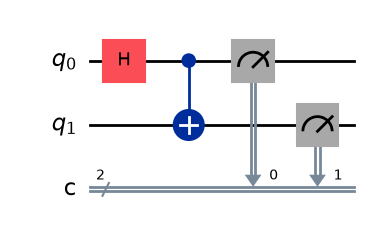

In [7]:
qr = QuantumRegister(2, "q")      # two qubits
cr = ClassicalRegister(2, "c")    # two classical bits
bell = QuantumCircuit(qr, cr)

bell.h(0)                         # superposition on qubit 0
bell.cx(0, 1)                     # CNOT: entangle qubit 0 (control) with qubit 1 (target)
bell.measure([0, 1], [0, 1])      # read both qubits into the classical bits

print(bell.draw("text"))
bell.draw("mpl")

Every gate is a matrix acting on the state. Qiskit can show the state a circuit prepares (before measurement):

In [8]:
bell_state = bell.remove_final_measurements(inplace=False)
Statevector(bell_state).draw("latex")

<IPython.core.display.Latex object>

### Writing down single-qubit states

A classical bit is either 0 or 1. A **qubit** can be in $\vert0\rangle$, in $\vert1\rangle$, or in a linear combination of the two. This is **superposition**, and the most general single-qubit state can be written as

$$\vert\psi\rangle = \sqrt{1-p}\,\vert0\rangle + e^{i \phi} \sqrt{p}\,\vert1\rangle$$

Measuring this qubit gives $1$ with probability $p$ and $0$ with probability $1-p$; the probabilities add up to $1$, so no other outcome exists.

The second parameter, $\phi$, is the **relative phase** between $\vert0\rangle$ and $\vert1\rangle$. It doesn't change the measurement probabilities directly, but it is what makes interference possible, and interference is what quantum algorithms exploit.

### Visualizing quantum states

We'll use the `qsphere` to visualize states. The top of the sphere is $\vert0\rangle$ and the bottom is $\vert1\rangle$; the size of each dot shows its probability and the color shows its phase.

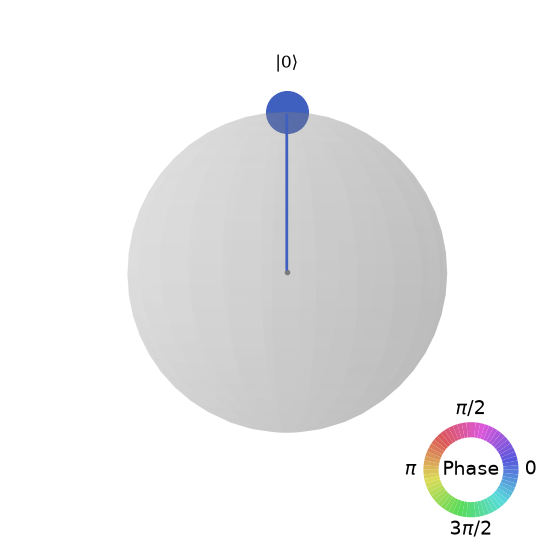

In [9]:
# visualize |0>
sv = Statevector([1, 0])
plot_state_qsphere(sv)

You get exactly the same qsphere from a circuit, because every qubit in Qiskit starts in $|0\rangle$:

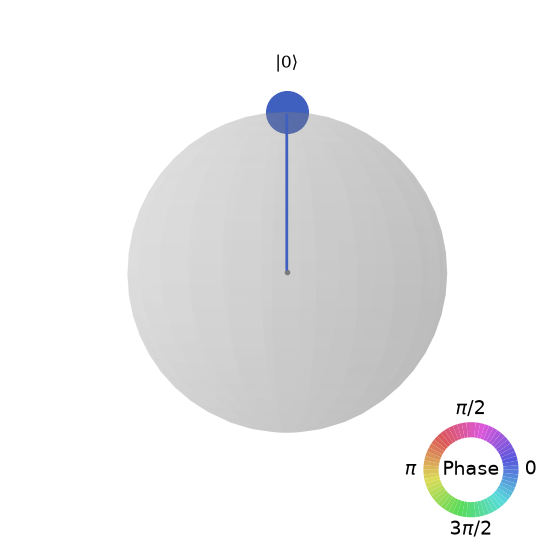

In [10]:
qc1 = QuantumCircuit(1)
sv = Statevector(qc1)
plot_state_qsphere(sv)

Now let's visualize the $|1\rangle$ state:

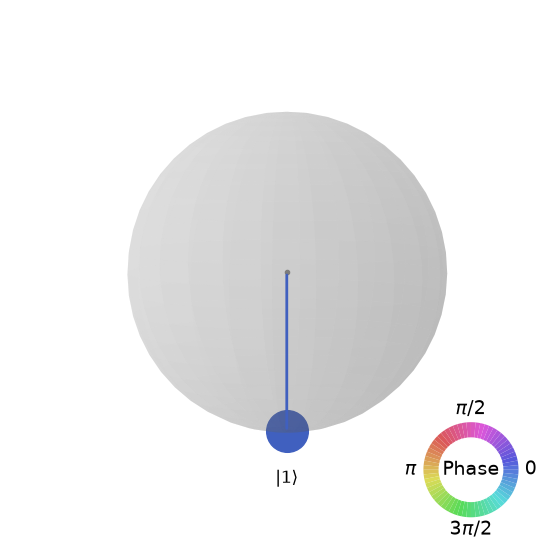

In [11]:
# visualize |1>
sv = Statevector([0, 1])
plot_state_qsphere(sv)

The equal superposition with $\phi = 0$ and $p = 1/2$ shows up as two dots. They are smaller than before because each outcome now has probability $1/2$.

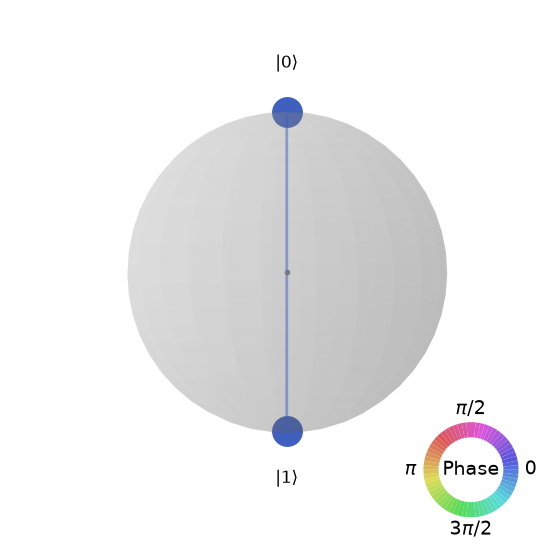

In [12]:
# visualize 1/sqrt(2)|0> + 1/sqrt(2)|1>
sv = Statevector([1 / sqrt(2), 1 / sqrt(2)])
plot_state_qsphere(sv)

When the relative phase is non-zero, the qsphere shows it as a color. Here is $\phi = 90^\circ$ with $p = 1/2$:

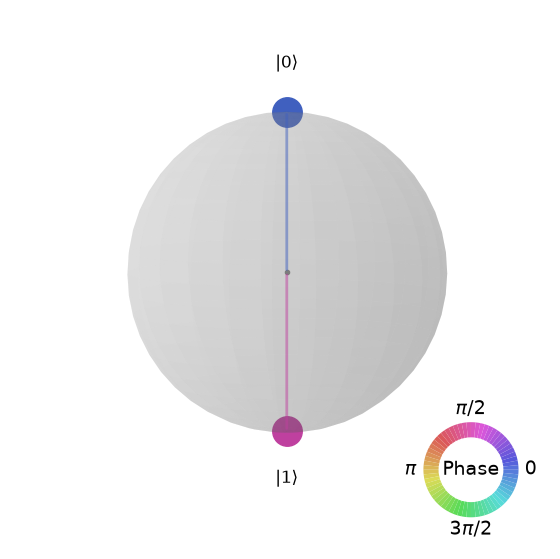

In [13]:
sv = Statevector([1 / sqrt(2), 1j / sqrt(2)])
plot_state_qsphere(sv)

The same state on the Bloch sphere, another common picture for a single qubit:

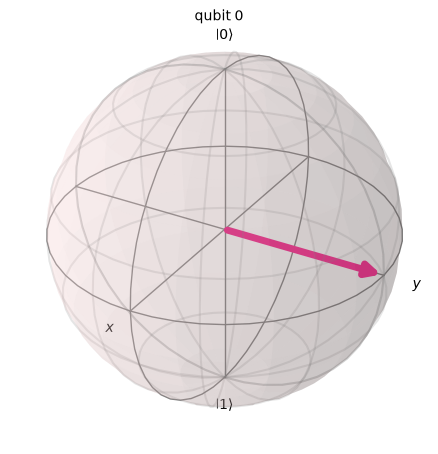

In [14]:
plot_bloch_multivector(Statevector([1 / sqrt(2), 1j / sqrt(2)]))

### Manipulating qubits

Qubits are manipulated with **quantum gates**. Two gates change $p$:

1. **$X$ gate**: flips $\vert0\rangle \leftrightarrow \vert1\rangle$, like a classical NOT (it changes $p$ to $1-p$).
2. **$H$ gate** (Hadamard): takes $\vert0\rangle$ to $\vert+\rangle = \frac{1}{\sqrt{2}}\left(\vert0\rangle + \vert1\rangle\right)$, i.e. from $p=0$ to $p=1/2$ with $\phi=0$. Because the result is a superposition, $H$ is a genuinely quantum operation.

Neither changes $\phi$. The figure shows how these and the phase gates move a state around the qsphere:

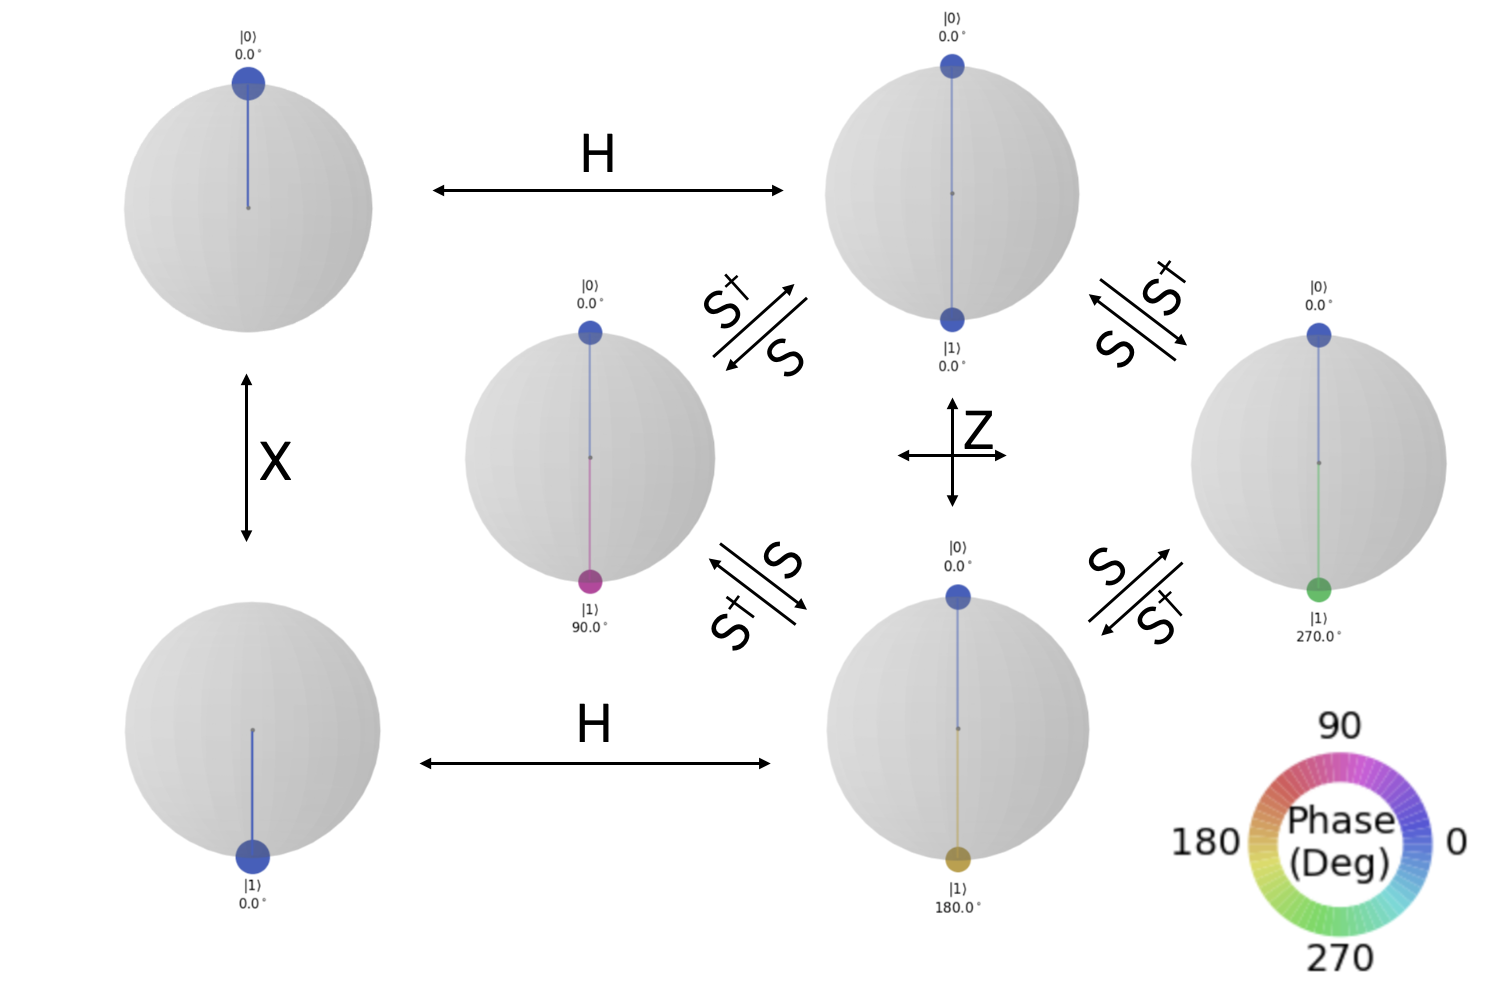

Starting from $\vert+\rangle$, other gates change the phase: $S$ adds $90^\circ$ to $\phi$, $Z$ adds $180^\circ$, and $S^\dagger$ (S-dagger, `sdg`) subtracts $90^\circ$. The $Y$ gate applies both a bit flip and a phase flip.

To build intuition, try the gates $X$, $Y$, $Z$, $H$, $S$, $S^\dagger$ in the [IBM Quantum Composer](https://quantum.cloud.ibm.com/composer): pick a gate, drop it on qubit 0, and watch the state change. The Composer also shows the matching Qiskit code.

To go deeper, see [Quantum Information (single systems)](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/quantum-information) in John Watrous's [Basics of Quantum Information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information) course.

In [15]:
def check(qc, target, name="state"):
    # Compare the circuit's state with the target (ignoring an overall global phase)
    ok = Statevector(qc).equiv(Statevector(target))
    print(f"{name}: {'correct! 🎉' if ok else 'not yet, keep trying'}")

### Practice: quantum circuits using single-qubit gates

Four small practices to reach different states on the qsphere. Use the Composer and paste its code, or combine these lines directly:

    qc.x(0)    # bit flip
    qc.y(0)    # bit and phase flip
    qc.z(0)    # phase flip
    qc.h(0)    # superposition
    qc.s(0)    # phase rotation by pi/2 (90 degrees)
    qc.sdg(0)  # phase rotation by -pi/2 (-90 degrees)

The `(0)` means the gate acts on qubit `q0`, the first (and here only) qubit.

#### i) Bit flip: reach $\vert1\rangle$ starting from $\vert0\rangle$.

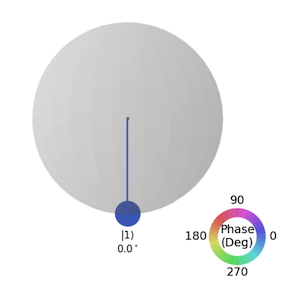

i) |1>: correct! 🎉


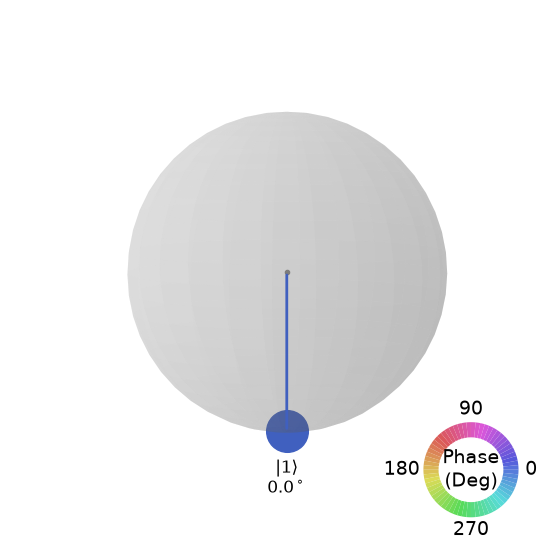

In [16]:
def create_circuit():
    qc = QuantumCircuit(1)
    qc.x(0)          # bit flip |0> -> |1>
    return qc

qc2 = create_circuit()
state = Statevector(qc2)
check(qc2, [0, 1], "i) |1>")
plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True)

#### ii) Superposition: reach $|+\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle + |1\rangle\right)$.

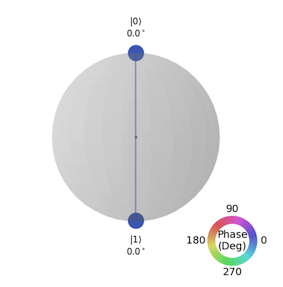

ii) |+>: correct! 🎉


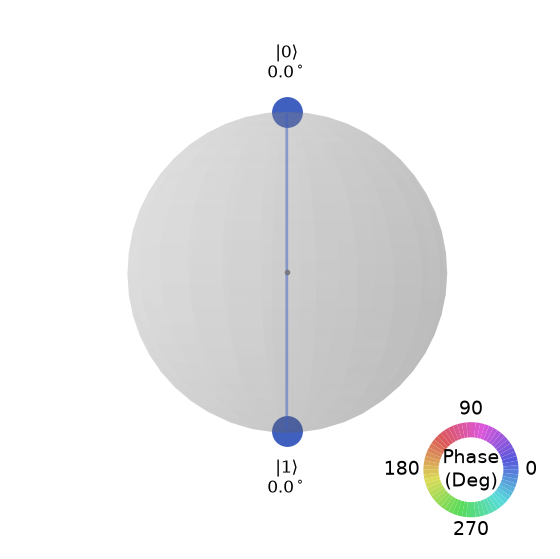

In [17]:
def create_circuit2():
    qc = QuantumCircuit(1)
    qc.h(0)          # Hadamard: |0> -> |+>
    return qc

qc3 = create_circuit2()
state = Statevector(qc3)
check(qc3, [1 / sqrt(2), 1 / sqrt(2)], "ii) |+>")
plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True)

#### iii) Combine the two: reach $|-\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle - |1\rangle\right)$.

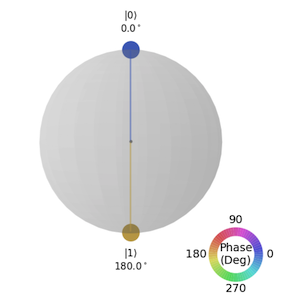

Can you combine the two previous tasks?

iii) |->: correct! 🎉


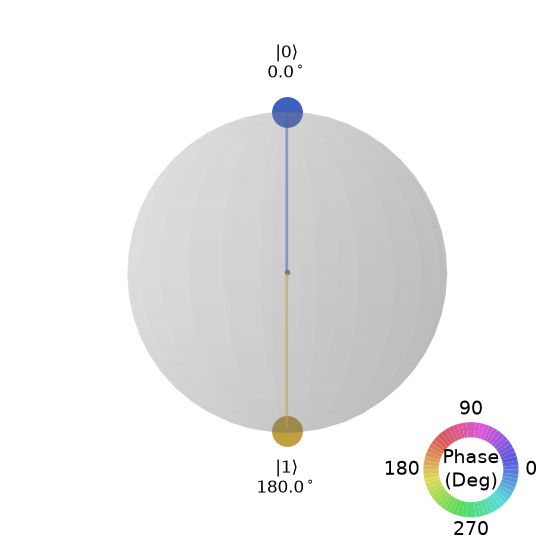

In [18]:
def create_circuit3():
    qc = QuantumCircuit(1)
    qc.x(0)          # |0> -> |1>
    qc.h(0)          # |1> -> |->   (h then z works too)
    return qc

qc4 = create_circuit3()
state = Statevector(qc4)
check(qc4, [1 / sqrt(2), -1 / sqrt(2)], "iii) |->")
plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True)

#### iv) Complex amplitudes: reach $|\circlearrowleft\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle - i|1\rangle\right)$.

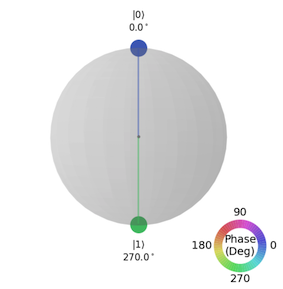

iv) |↺>: correct! 🎉


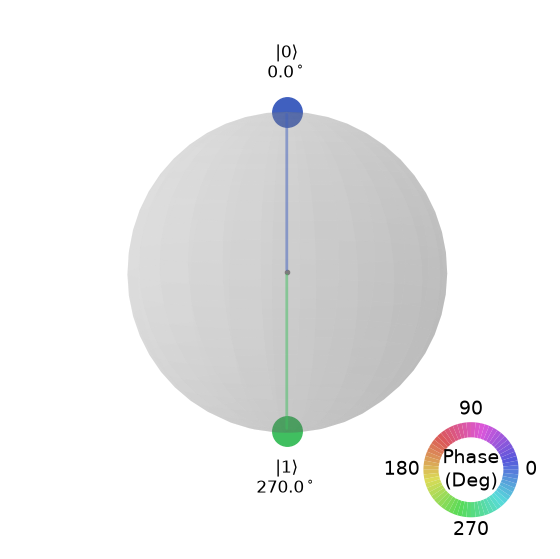

In [19]:
def create_circuit4():
    qc = QuantumCircuit(1)
    qc.h(0)          # |0> -> |+>
    qc.sdg(0)        # subtract 90 degrees of phase: |+> -> (|0> - i|1>)/sqrt(2)
    return qc

qc5 = create_circuit4()
state = Statevector(qc5)
check(qc5, [1 / sqrt(2), -1j / sqrt(2)], "iv) |↺>")
plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True)

## 4. Quantum quiz with multi-qubit gates

Great job! Now let's use gates that act on more than one qubit. The basic two-qubit gates are

    qc.cx(c, t)      # controlled-X (CNOT) with control qubit c and target qubit t
    qc.cz(c, t)      # controlled-Z with control qubit c and target qubit t
    qc.swap(a, b)    # SWAP: exchanges the states of qubits a and b

For more, see [Quantum Information (multiple systems)](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/quantum-information) in the same course.

A general two-qubit state is $a|00\rangle + b |01\rangle + c |10\rangle + d|11\rangle$, where the complex numbers $a, b, c, d$ give the probability of each outcome through $|a|^2$, $|b|^2$, and so on. So the qsphere can now show up to four dots. (Qiskit writes bitstrings right-to-left: in $|01\rangle$, qubit 0 is 1 and qubit 1 is 0.)

The CNOT gate flips the target qubit only when the control qubit is $|1\rangle$. With classical inputs it behaves like a classical gate, but if the control is first put in $|+\rangle$ with a Hadamard, CNOT creates **entanglement**. With the target starting in $|0\rangle$, the result is $|\Phi^+\rangle$, one of the [Bell states](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/quantum-information#bell-states).

#### i) Construct the Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right)$.

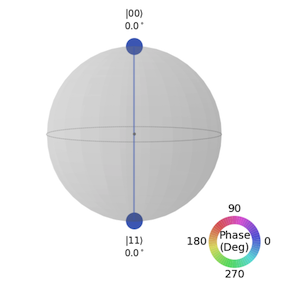

This state gives "00" or "11" with probability $\frac{1}{2}$ each: the two qubits' outcomes are perfectly correlated.

Quiz i) |Φ+>: correct! 🎉


<IPython.core.display.Latex object>

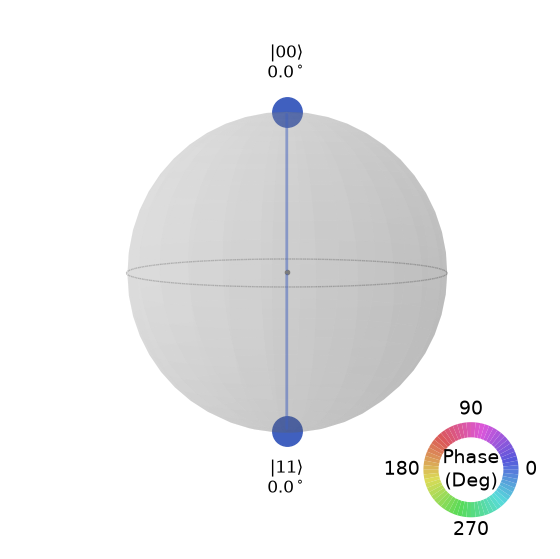

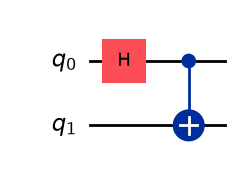

In [20]:
def create_circuit5():
    qc = QuantumCircuit(2)
    qc.h(0)          # superposition on the control qubit
    qc.cx(0, 1)      # entangle
    return qc

qc6 = create_circuit5()
check(qc6, [1 / sqrt(2), 0, 0, 1 / sqrt(2)], "Quiz i) |Φ+>")

state = Statevector(qc6)       # final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc6.draw(output="mpl")         # draw the circuit

Next, create perfectly **anti**-correlated qubits. The minus sign is a relative phase between the two terms.

#### ii) Construct the Bell state $\vert\Psi^-\rangle = \frac{1}{\sqrt{2}}\left(\vert01\rangle - \vert10\rangle\right)$.

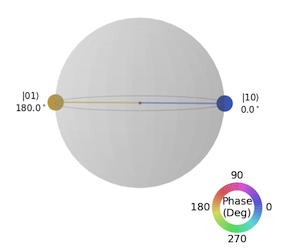

If your colors come out swapped compared with this picture, your state differs only by an overall (global) phase, which is physically the same state. The `check` line tells you whether you got it.

Quiz ii) |Ψ->: correct! 🎉


<IPython.core.display.Latex object>

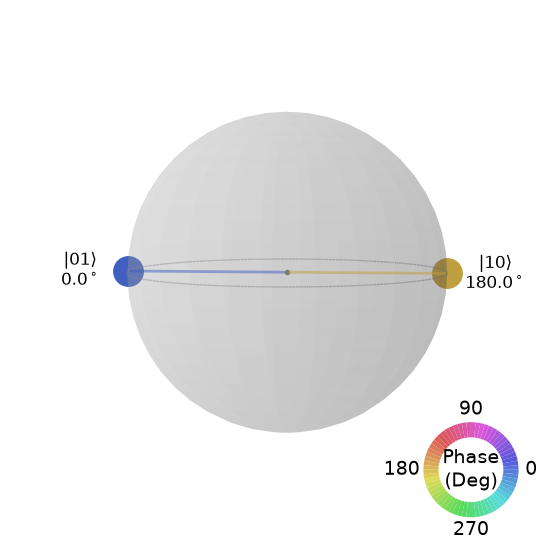

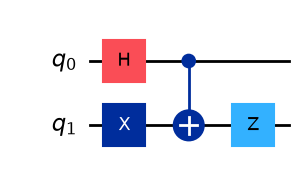

In [21]:
def create_circuit6():
    qc = QuantumCircuit(2)
    qc.h(0)          # (|00> + |01>)/sqrt(2)
    qc.x(1)          # (|10> + |11>)/sqrt(2)
    qc.cx(0, 1)      # (|10> + |01>)/sqrt(2)   anti-correlated
    qc.z(1)          # (|01> - |10>)/sqrt(2)   minus sign on the |10> term
    return qc

qc7 = create_circuit6()
check(qc7, [0, 1 / sqrt(2), -1 / sqrt(2), 0], "Quiz ii) |Ψ->")

state = Statevector(qc7)       # final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc7.draw(output="mpl")         # draw the circuit

#### iii) You are given the circuit in the function below. Swap the states of the first and second qubit to get this qsphere.

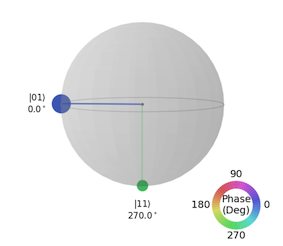

Quiz iii) swap: correct! 🎉


<IPython.core.display.Latex object>

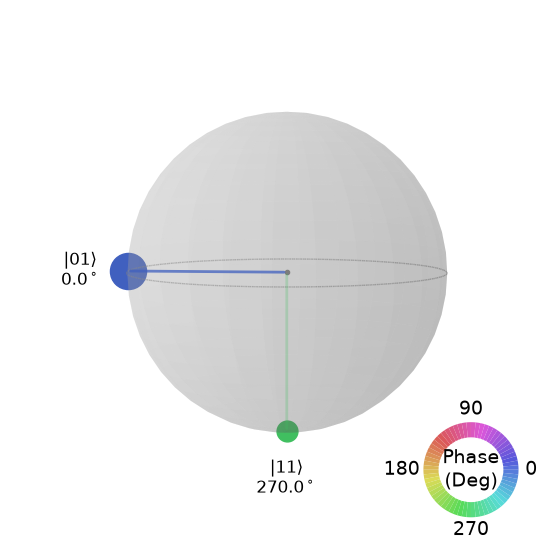

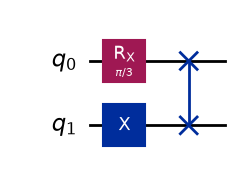

In [22]:
def create_circuit7():
    qc = QuantumCircuit(2)
    qc.rx(np.pi / 3, 0)
    qc.x(1)
    return qc

qc8 = create_circuit7()
qc8.swap(0, 1)       # exchange the two qubits' states

check(qc8, [0, np.cos(np.pi / 6), 0, -1j * np.sin(np.pi / 6)], "Quiz iii) swap")

state = Statevector(qc8)       # final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc8.draw(output="mpl")         # draw the circuit

#### iv) Write a program from scratch that creates the three-qubit GHZ state $\vert \text{GHZ}\rangle = \frac{1}{\sqrt{2}} \left(|000\rangle + |111 \rangle \right)$.

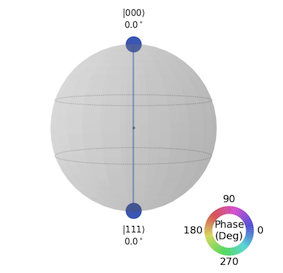

Quiz iv) |GHZ>: correct! 🎉


<IPython.core.display.Latex object>

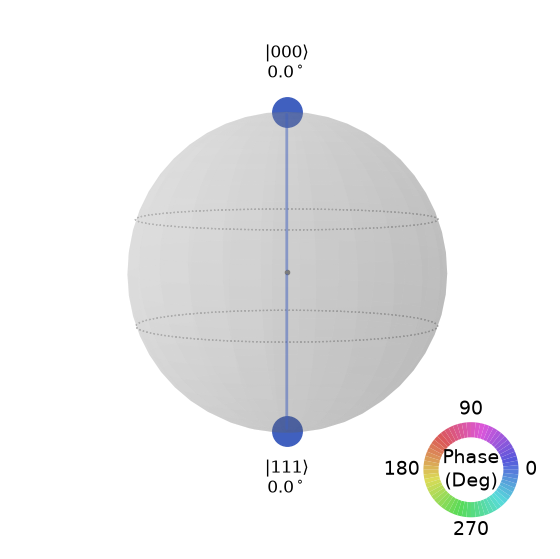

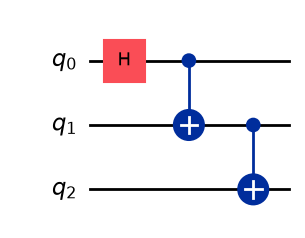

In [23]:
def create_circuit8():
    qc = QuantumCircuit(3)
    qc.h(0)          # superposition on qubit 0
    qc.cx(0, 1)      # copy the correlation to qubit 1
    qc.cx(1, 2)      # ...and to qubit 2
    return qc

qc9 = create_circuit8()
check(qc9, [1 / sqrt(2), 0, 0, 0, 0, 0, 0, 1 / sqrt(2)], "Quiz iv) |GHZ>")

state = Statevector(qc9)       # final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc9.draw(output="mpl")         # draw the circuit

## 5. Run your circuits on a simulator and a real quantum computer

We can build circuits and inspect their states. Now for the most exciting part: **running** them and looking at measured results.

We'll follow a **Qiskit pattern**, the general workflow for any quantum program:

1. **Map** the problem to quantum circuits and operators
2. **Optimize** for the target hardware
3. **Execute** on the target hardware
4. **Post-process** the results

Sections 3 and 4 were Step 1 (Map). Let's collect the nine circuits we built:

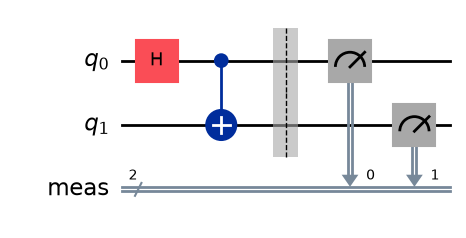

In [24]:
circ = [qc1, qc2, qc3, qc4, qc5, qc6, qc7, qc8, qc9]
names = ["|0>", "|1>", "|+>", "|->", "|↺>", "Φ+", "Ψ-", "swap", "GHZ"]

# Add a measurement to a copy of each circuit (the originals stay measurement-free)
measured = [qc.measure_all(inplace=False) for qc in circ]
measured[5].draw("mpl")

### Choose where to run

* `USE_REAL_HARDWARE = True` sends the job to the least busy IBM quantum computer you have access to (needs Section 2).
* `USE_REAL_HARDWARE = False` uses `FakeKingston`, a simulator that copies the qubit layout, native gates, and error rates of the real 156-qubit **ibm_kingston** (an IBM Heron r2 processor). Results look like real hardware, without an account or queue.

In [25]:
USE_REAL_HARDWARE = True   # <- set to True for the real quantum computer

if USE_REAL_HARDWARE:
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False)
else:
    from qiskit_ibm_runtime.fake_provider import FakeKingston
    backend = FakeKingston()

print(f"Backend: {backend.name}  ({backend.num_qubits} qubits)")

Backend: ibm_kingston  (156 qubits)


### Optimize

A real device only understands a few **native gates** (on Heron: `rz`, `sx`, `x`, `cz`), and two-qubit gates only work between **physically connected** qubits. The **pass manager** *transpiles* each circuit: it picks good physical qubits, routes around the connectivity, rewrites every gate in native gates, and simplifies the result. `optimization_level` goes from 0 to 3; higher means more optimization.

Bell circuit, as written:      {'measure': 2, 'h': 1, 'cx': 1, 'barrier': 1}
Bell circuit, as the QPU runs: {'rz': 5, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1}
Physical qubits used:          [149, 148]


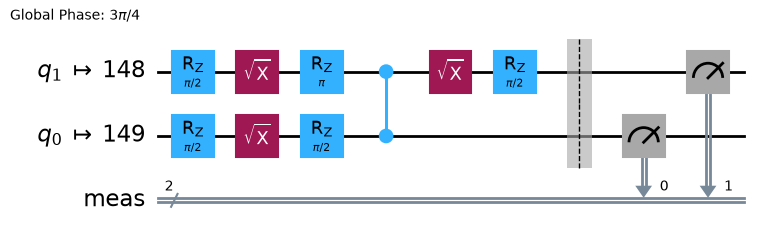

In [26]:
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_circuits = [pm.run(qc) for qc in measured]

print("Bell circuit, as written:     ", dict(measured[5].count_ops()))
print("Bell circuit, as the QPU runs:", dict(isa_circuits[5].count_ops()))
print("Physical qubits used:         ", isa_circuits[5].layout.final_index_layout())
isa_circuits[5].draw("mpl", idle_wires=False)

`H` and `CX` were rewritten into `rz`, `sx`, and `cz`, and our virtual qubits were placed on specific physical qubits of the chip.

### Execute on a simulator

Before spending QPU time, run everything on an ideal, noise-free simulator ([Qiskit Aer](https://qiskit.github.io/qiskit-aer/)). We use the **Sampler** primitive, which returns counts of measured bitstrings. (The other primitive, **Estimator**, returns expectation values of observables.) The same `Sampler` code works for the simulator and the real device; only `mode` changes.

In [27]:
ideal_result = Sampler(mode=AerSimulator()).run(measured, shots=4096).result()
ideal_counts = [ideal_result[k].data.meas.get_counts() for k in range(len(circ))]

for name, counts in zip(names, ideal_counts):
    print(f"{name:>5}: {dict(sorted(counts.items()))}")

  |0>: {'0': 4096}
  |1>: {'1': 4096}
  |+>: {'0': 2072, '1': 2024}
  |->: {'0': 2039, '1': 2057}
  |↺>: {'0': 2039, '1': 2057}
   Φ+: {'00': 2057, '11': 2039}
   Ψ-: {'01': 2021, '10': 2075}
 swap: {'01': 3064, '11': 1032}
  GHZ: {'000': 2034, '111': 2062}


### Execute on the quantum computer

On real hardware your job waits in a queue. Print and save the `job_id`: you can close the notebook and fetch the result later with `service.job(job_id)`.

In [28]:
def run_sampler(circuits, shots=4096):
    # New client-side Sampler first; fall back to the legacy SamplerV2 if this
    # account or backend doesn't support it yet.
    try:
        return Sampler(mode=backend).run(circuits, shots=shots)
    except Exception as err:
        print(f"Client-side Sampler unavailable ({type(err).__name__}); using SamplerV2.")
        from qiskit_ibm_runtime import SamplerV2
        return SamplerV2(mode=backend).run(circuits, shots=shots)

job = run_sampler(isa_circuits)
job_id = job.job_id()
print("job id:", job_id)
job.status()

job id: db6s4ssvf2bc73d1nuk0


'QUEUED'

In [29]:
# Retrieve the result (on real hardware this works even after restarting the kernel)
if USE_REAL_HARDWARE:
    job = service.job(job_id)
result = job.result()
counts_all = [result[k].data.meas.get_counts() for k in range(len(circ))]

### Post-process

Finally, let's plot what the device measured, grouped by the kind of state we prepared.

**Single-qubit basis states**

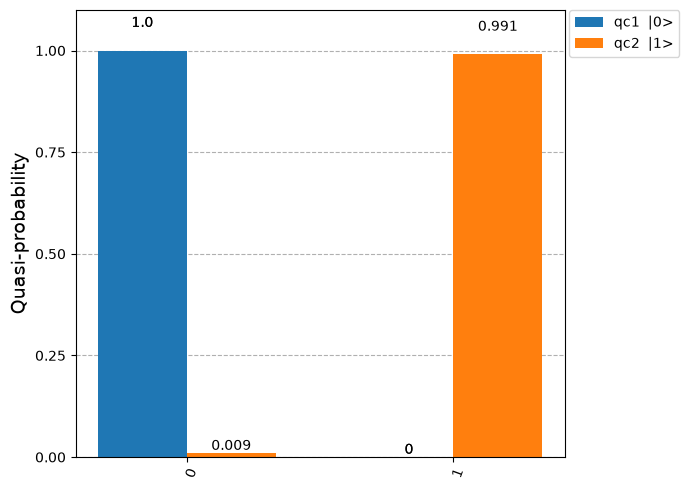

In [30]:
plot_distribution([counts_all[0], counts_all[1]], legend=["qc1  |0>", "qc2  |1>"])

**Single-qubit superpositions**

All three give roughly 50/50! Measuring in the computational basis reveals $|a|^2$ and $|b|^2$ but **not the phase** $\phi$, so $|+\rangle$, $|-\rangle$ and $|\circlearrowleft\rangle$ look identical here. Telling them apart takes extra gates before the measurement, which is how interference-based algorithms work.

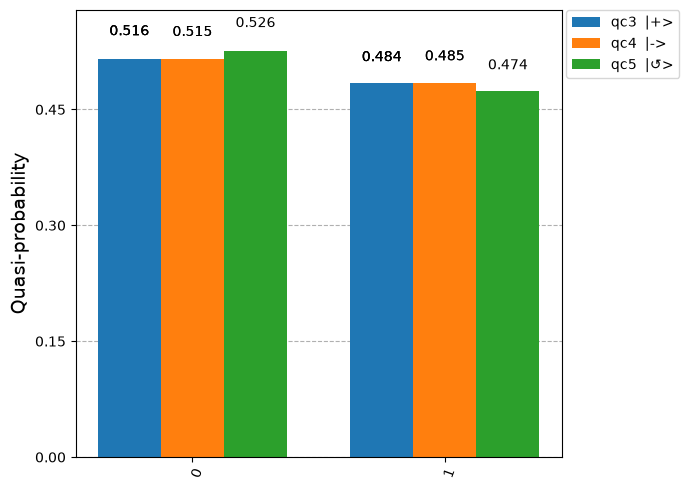

In [31]:
plot_distribution([counts_all[2], counts_all[3], counts_all[4]], legend=["qc3  |+>", "qc4  |->", "qc5  |↺>"])

**Two-qubit states**

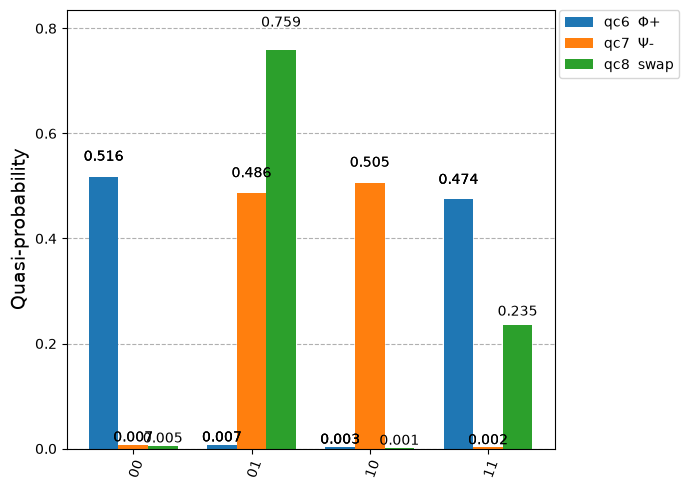

In [32]:
plot_distribution([counts_all[5], counts_all[6], counts_all[7]], legend=["qc6  Φ+", "qc7  Ψ-", "qc8  swap"])

**Three-qubit state**

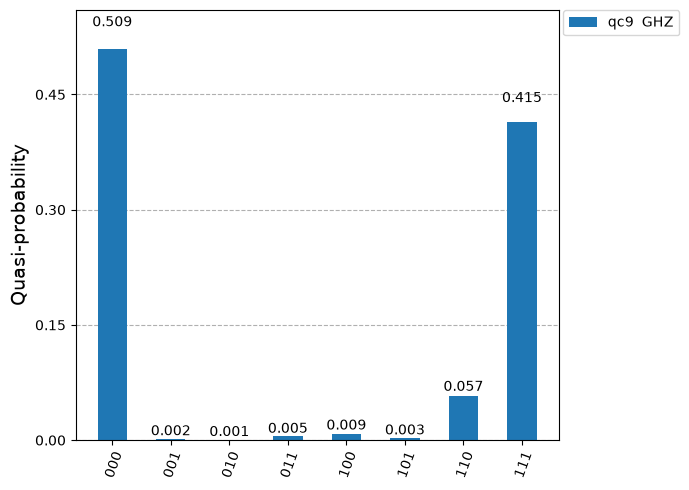

In [33]:
plot_distribution(counts_all[8], legend=["qc9  GHZ"])

### Simulator vs. quantum computer

Ideally the Bell and GHZ states only ever produce all-equal bitstrings. Any other outcome on the device is **noise**: imperfect gates, readout errors, and decoherence.

  Φ+: ideal 1.000   ibm_kingston 0.991
 GHZ: ideal 1.000   ibm_kingston 0.924


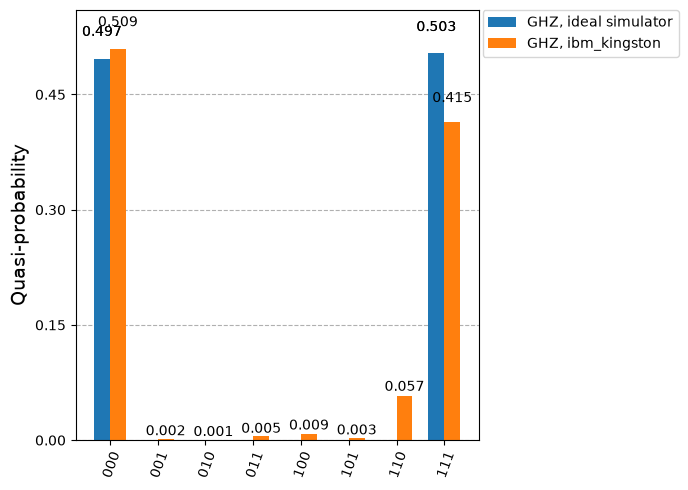

In [34]:
def share(counts, keys):
    return sum(counts.get(k, 0) for k in keys) / sum(counts.values())

for idx, keys in [(5, ["00", "11"]), (8, ["000", "111"])]:
    print(f"{names[idx]:>4}: ideal {share(ideal_counts[idx], keys):.3f}   {backend.name} {share(counts_all[idx], keys):.3f}")

plot_distribution([ideal_counts[8], counts_all[8]], legend=["GHZ, ideal simulator", f"GHZ, {backend.name}"])

## 6. Further challenge

Did you spot noise in the device results? Reducing it is one of the most active research areas in quantum computing. Try the [error suppression and mitigation options](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques) of the Sampler and see how the results change. (These options use more QPU time.)

In [35]:
sampler_em = Sampler(mode=backend)
sampler_em.options.dynamical_decoupling.enable = True       # protect idle qubits with pulse sequences
sampler_em.options.dynamical_decoupling.sequence_type = "XY4"
sampler_em.options.twirling.enable_gates = True             # randomize two-qubit gate errors
sampler_em.options.twirling.enable_measure = True           # randomize readout errors

# Uncomment on real hardware, then compare with counts_all:
# job_em = sampler_em.run(isa_circuits, shots=4096)
# print(job_em.job_id())

**Original notebook:** *Qiskit 101 Hands-on* ("First Step into Quantum Computing"), created by Sophy Shin and reviewed by Nate Earnest-Noble, IBM.

**Adapted for Qiskit Fall Fest 2026 at UC Irvine** by Van Tien Nguyen (University of Texas at San Antonio). Changes: updated for Qiskit 2.x and qiskit-ibm-runtime 0.50 (client-side Sampler, `ibm_quantum_platform` channel); added a circuit-anatomy section, Bloch-sphere view, answer checks, a simulator run, a transpilation step, a noisy-simulator option, and a simulator-vs-hardware comparison; fixed the undefined circuit list and the job-retrieval cell; edited the text.

<div class="alert alert-info">

© IBM Corp., 2025

This is licensed under the Apache License, Version 2.0. You may obtain a copy of this license in the LICENSE file in the root directory of this source tree or at http://www.apache.org/licenses/LICENSE-2.0.

Any modifications or derivative works of this must retain this copyright notice, and modified files need to carry a notice indicating that they have been altered from the originals.
</div>